In [67]:
import pandas as pd 
import matplotlib.pyplot as plt 
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler


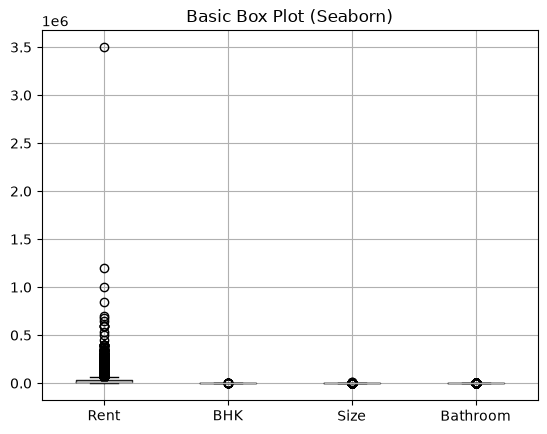

In [68]:
df=pd.read_csv("House_Rent_Dataset.csv")

df =df [["Rent","BHK","Size","Floor","City","Bathroom"]]
df
df.isnull().sum()
df.duplicated().sum()     # number of duplicate rows
df.drop_duplicates()  # drop duplicate rows

# Create the box plot
df.boxplot(column=["Rent","BHK","Size","Bathroom"])

# Add title
plt.title("Basic Box Plot (Seaborn)")

# Display the plot
plt.show()


In [69]:
q1 = df["Rent"].quantile(0.25)
q3 = df["Rent"].quantile(0.75)
iqr = q3 - q1

low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr

outliers = df[(df["Rent"] < low) | (df["Rent"] > high)]
print("Limits:", low, high)
print("Outliers:", len(outliers))
print (outliers)

print("Total rows:", len(df))
print("Percentage:", round(len(outliers) / len(df) * 100, 2), "%")

Limits: -24500.0 67500.0
Outliers: 520
        Rent  BHK  Size            Floor       City  Bathroom
104   180000    2   950  Ground out of 1    Kolkata         2
525    70000    2   750      4 out of 10     Mumbai         2
527    75000    3  1100      2 out of 13     Mumbai         3
530   160000    2   800     14 out of 14     Mumbai         2
531   300000    4  1600     43 out of 78     Mumbai         5
...      ...  ...   ...              ...        ...       ...
4523   70000    3  2780      4 out of 26  Hyderabad         3
4543  200000    4  4761      1 out of 35  Hyderabad         6
4648   80000    6  4500       1 out of 2  Hyderabad         6
4669  140000    4  3789      9 out of 22  Hyderabad         5
4716  110000    4  3250     12 out of 17  Hyderabad         5

[520 rows x 6 columns]
Total rows: 4746
Percentage: 10.96 %


In [70]:
# Log-transform the rent column and  encoding the categorical variable "City" using one-hot encoding. The floor column is also processed to convert its values into numeric 
df["Rent_log"] = np.log1p(df["Rent"])
df["Rent_log"]
df = pd.get_dummies(df, columns=["City"], drop_first=True)
city_cols = [c for c in df.columns if c.startswith("City_")]
df[city_cols] = df[city_cols].astype(int)
df.head()
X = df.drop(["Rent", "Rent_log"], axis=1)
y = df["Rent_log"]
print(X.columns.tolist())
first_part = df["Floor"].str.split(" out of").str[0]
df["Floor"] = first_part
df["Floor"] = df["Floor"].replace({"Ground": "0", "Upper Basement": "-1", "Lower Basement": "-2"})
df["Floor"] = pd.to_numeric(df["Floor"], errors="coerce")
df["Floor"].unique()
df.dtypes


['BHK', 'Size', 'Floor', 'Bathroom', 'City_Chennai', 'City_Delhi', 'City_Hyderabad', 'City_Kolkata', 'City_Mumbai']


Rent                int64
BHK                 int64
Size                int64
Floor               int64
Bathroom            int64
Rent_log          float64
City_Chennai        int64
City_Delhi          int64
City_Hyderabad      int64
City_Kolkata        int64
City_Mumbai         int64
dtype: object

In [71]:
#separate the features  X and target variable Y
X = df.drop(["Rent", "Rent_log"], axis=1)
y = df["Rent_log"]

print(X.columns.tolist())
print(X.isnull().sum())
print(X.dtypes)


['BHK', 'Size', 'Floor', 'Bathroom', 'City_Chennai', 'City_Delhi', 'City_Hyderabad', 'City_Kolkata', 'City_Mumbai']
BHK               0
Size              0
Floor             0
Bathroom          0
City_Chennai      0
City_Delhi        0
City_Hyderabad    0
City_Kolkata      0
City_Mumbai       0
dtype: int64
BHK               int64
Size              int64
Floor             int64
Bathroom          int64
City_Chennai      int64
City_Delhi        int64
City_Hyderabad    int64
City_Kolkata      int64
City_Mumbai       int64
dtype: object


In [72]:
#split the dataset into training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (3796, 9)
X_test: (950, 9)
y_train: (3796,)
y_test: (950,)


In [73]:
#scaling the features using StandardScaler
num_cols = ["Size", "BHK", "Bathroom", "Floor"]

X_train = X_train.copy()
X_test = X_test.copy()

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])  

In [74]:
#checking the results of scaling

print(X_train[num_cols].mean())
print(X_train[num_cols].std())

Size        4.913527e-17
BHK        -9.593076e-17
Bathroom    9.125121e-17
Floor       7.487279e-18
dtype: float64
Size        1.000132
BHK         1.000132
Bathroom    1.000132
Floor       1.000132
dtype: float64


In [ ]:
#starting the model training 
